In [62]:
import os 
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.core.interactiveshell import InteractiveShell  
from ipywidgets import interact  
InteractiveShell.ast_node_interactivity = "all"   # type: ignore
import ipywidgets as widgets
from ipywidgets import interact 
from pandas import Index
from typing import Any

In [63]:
def show_col_summary(column: Any, frame):
    print(frame[column].describe())

def show_summary(dfs: list[pd.DataFrame], v_dir: Path):
    print(f"Results aggregated over {v_dir.stem} in {v_dir.parent.parent.stem}/{v_dir.parent.stem}")
    for frame in dfs:
        interact(show_col_summary, frame=frame, column=list(frame.columns))
        frame 


In [ ]:

def save_all(metrics: list[dict[str, np.ndarray | str]], header: list[str] | Index, v_dir: Path, steps: pd.DataFrame) -> None:
        for metric_dict in metrics: 
                name = metric_dict["name"]
                total_metric = metric_dict["values"]
                custom_header = list(map(lambda title: f"{name}_{title}", header))
                total_metric_df = pd.DataFrame(total_metric, columns=custom_header)
                total_metric_df = pd.concat([steps,total_metric_df], axis=1)
                summary_save_dir = v_dir.resolve() / f"{name}.csv"
                total_metric_df.to_csv(summary_save_dir)
                print(f"Results aggregated over {v_dir.stem} in {v_dir.parent.parent.stem}/{v_dir.parent.stem}")
                cols = list(total_metric_df.columns)
                for i, _ in enumerate(cols[1:]):
                        total_metric_df.plot(y=cols[i])

        plt.show()

def store_summary_metrics(prefix: str, sum: np.ndarray, sum_sq: np.ndarray, header: list[str] | Index, v_dir: Path, steps: pd.DataFrame, num_metrics: int) -> None:
        # For this/each experiment save this in the parent directory as a summary for runs
        total_mean = sum / num_metrics
        total_var = sum_sq / num_metrics - (np.square(total_mean))
        total_std = np.sqrt(total_var)
        mean_data = dict(values=total_mean, name=f"{prefix}_mean")
        std_data = dict(values=total_std, name=f"{prefix}_std_dev")
        save_all([mean_data, std_data], header, v_dir, steps)

In [ ]:
def all_corr_store_metrics(dir: Path) -> pd.DataFrame:
    metrics = sorted(dir.rglob("*", case_sensitive=False))
    metrics_dfs = map(lambda m: pd.read_csv(m), metrics) 
    run_metrics = pd.concat(metrics_dfs, axis=0)
    return run_metrics

def process_gcs_metrics(v_dir: Path) -> None:
    run_dirs = sorted(v_dir.glob("run*", case_sensitive=False))
    for r_dir in run_dirs:
        gcs_metrics_dirs = sorted(r_dir.rglob("train/GCS*", case_sensitive=False))
        rgcs_metrics_dirs = sorted(r_dir.rglob("train/RGCS*", case_sensitive=False))
        # Concat metrics into a single stitch to store for train/gch_metrics.csv
        for g_dir, rg_dir in zip(gcs_metrics_dirs, rgcs_metrics_dirs):
            run_gcs_df = all_corr_store_metrics(g_dir)
            run_rgcs_df = all_corr_store_metrics(rg_dir)
            run_gcs_df.to_csv(g_dir.parent.resolve() / "run_gcs")
            run_rgcs_df.to_csv(rg_dir.parent.resolve() / "run_rgcs")

        # Within 1 version perform summary stats 
        run_metrics_dirs = sorted(r_dir.rglob("run_rgcs.csv", case_sensitive=False))
        process_standard_metrics(run_metrics_dirs, "rgcs")
        
        run_metrics_dirs = sorted(r_dir.rglob("run_gcs.csv", case_sensitive=False))
        process_standard_metrics(run_metrics_dirs, "gcs")

In [ ]:
def process_standard_metrics(train_metrics_dirs: list[Path], prefix:str) -> None:
    num_metrics = len(train_metrics_dirs)

    # Sizes are unknown unless peeking is performed
    sum = np.zeros(0)
    sum_sq = np.zeros(0)
    steps = pd.DataFrame(np.zeros(0))
    header = [""]
    # Save initial path
    enumerated_metrics = enumerate(train_metrics_dirs)

    for i, train_metrics_path in enumerated_metrics:
        with open(train_metrics_path) as f:
            ncols = len(f.readline().split(','))
            
        data = pd.read_csv(train_metrics_path.resolve(), usecols=range(1,ncols))
        steps = pd.read_csv(train_metrics_path.resolve(), usecols=[0])
        metrics = np.asarray(data.values)
        if i == 0:
            sum = np.zeros_like(metrics)
            sum_sq = np.zeros_like(metrics)
            header = data.columns

        sum = np.sum([sum, metrics], axis=(0))
        sum_sq = np.sum([sum_sq, np.square(metrics)], axis=(0))

    store_summary_metrics(prefix, sum, sum_sq, header, train_metrics_dirs[0].parent, steps, num_metrics)

Results aggregated over v_0 in adam_class_imbalance_ratios/multijob


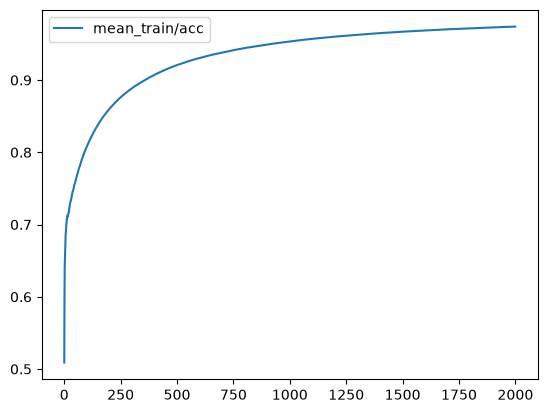

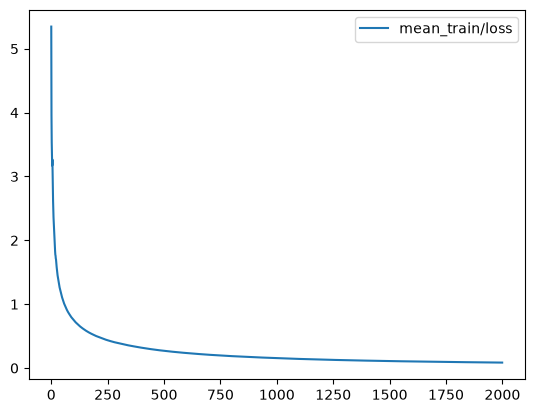

Results aggregated over v_0 in adam_class_imbalance_ratios/multijob


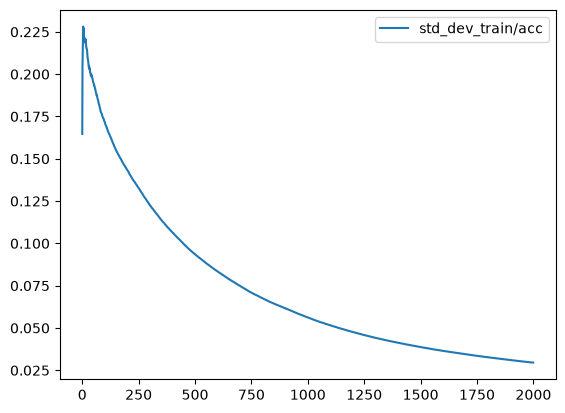

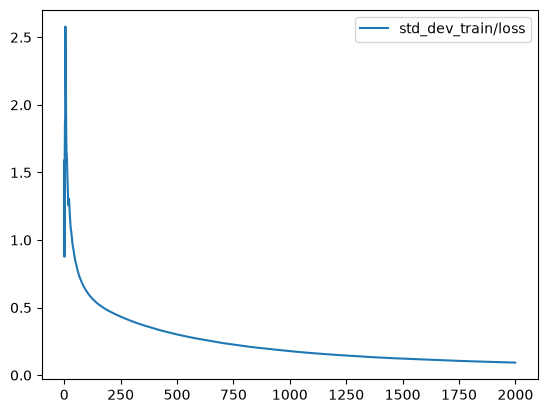

Results aggregated over v_0 in muon_class_imbalance_ratios/multijob


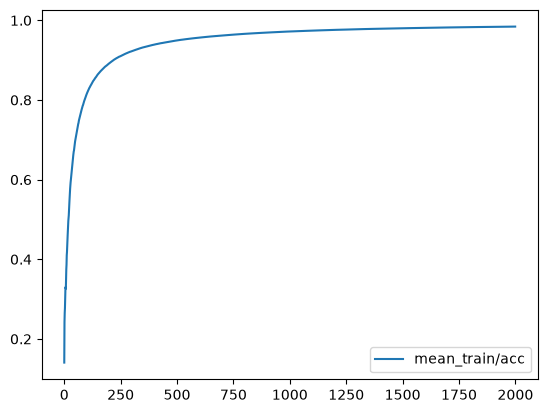

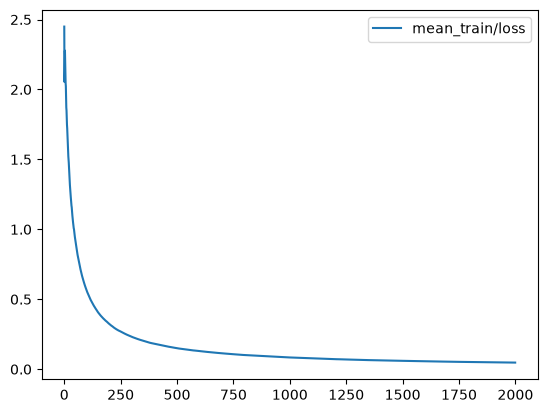

Results aggregated over v_0 in muon_class_imbalance_ratios/multijob


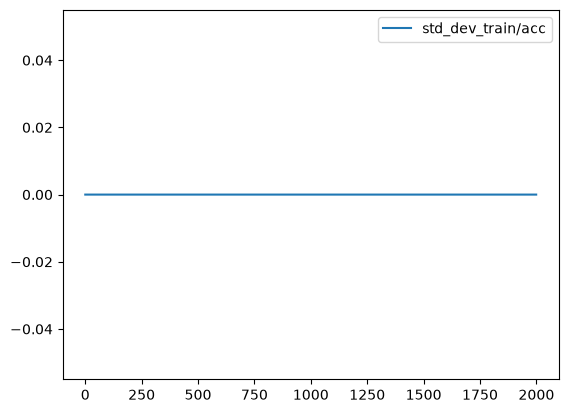

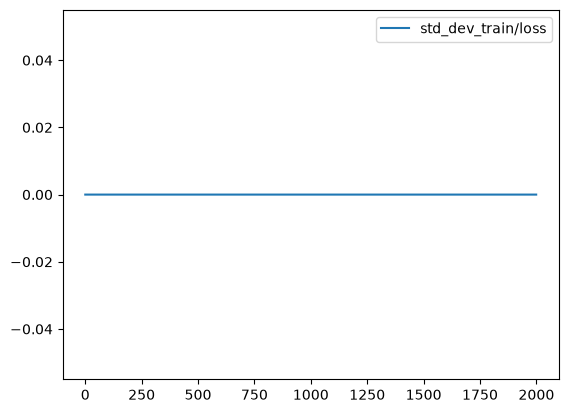

In [ ]:
outputs_dir = Path().resolve().parent / "outputs"

for experim_path in sorted(outputs_dir.iterdir()):
    version_dirs = sorted(experim_path.glob("multijob/v*"))
    for v_dir in version_dirs:
        train_metrics_dirs = sorted(v_dir.rglob("run*/train/metrics.csv", case_sensitive=False))
        process_standard_metrics(train_metrics_dirs, "standard")
        process_gcs_metrics(v_dir)